# EDA Step 1: Load and Audit Rice Yield Dataset

This notebook verifies the cleaned dataset handed off by Member 1.

Current purpose:
- Confirm dataset shape and columns
- Check missing values and duplicates
- Check categorical consistency
- Check province/island consistency
- Check basic numeric sanity
- Verify derived fertilizer total consistency

This step does not perform train/test splitting, preprocessing, augmentation, or modeling.

Important context:
- `province` is kept as an identifier for grouping and leave-one-province-out validation.
- `province` is not used as a trained feature.
- `island_group` is the intended geographic feature.
- `soil_ph` is simulated, anchored to plausible Philippine paddy-soil ranges, and should not be described as measured field data.

In [9]:
# load the dataset
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/processed/merged_rice_yield_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH.resolve()}\n"
    )

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head(5)

Shape: (287, 21)


,season_period,ecosystem,province,island_group,yield_mt_ha,area_harvested_ha,n_application_rate,p_application_rate,k_application_rate,grade_ammophos_16_20_0_kg_ha,...,grade_complete_14_14_14_kg_ha,grade_mop_0_0_60_kg_ha,grade_urea_46_0_0_kg_ha,total_fertilizer_kg_ha,fertilizer_diversification_index,rainfall_mm,temp_max_c,temp_min_c,solar_radiation_mj_m2,soil_ph
0,2021_Semester_2,Irrigated,Abra,Luzon,4.04,9899.0,84.93,13.98,5.82,30.93,...,23.35,0.00,100.40,160.96,1.017983,2122.3,29.555435,22.641848,17.195272,6.09
1,2021_Semester_2,Non-irrigated,Abra,Luzon,3.43,8834.0,84.93,13.98,5.82,30.93,...,23.35,0.00,100.40,160.96,1.017983,2122.3,29.555435,22.641848,17.195272,5.45
2,2021_Semester_2,Irrigated,Albay,Luzon,4.44,21509.0,109.12,18.62,18.37,4.42,...,70.19,0.83,101.15,177.51,0.831672,1678.6,28.278804,23.341304,16.282065,6.38
3,2021_Semester_2,Non-irrigated,Albay,Luzon,3.51,5392.0,109.12,18.62,18.37,4.42,...,70.19,0.83,101.15,177.51,0.831672,1678.6,28.278804,23.341304,16.282065,5.97
4,2021_Semester_2,Irrigated,Apayao,Luzon,3.72,7476.0,115.75,29.09,19.49,47.77,...,136.09,2.08,185.22,371.99,1.021278,1858.0,23.836957,17.834783,15.272391,6.36


In [10]:
# confirm expected columns
expected_columns = [
    "season_period",
    "ecosystem",
    "province",
    "island_group",
    "yield_mt_ha",
    "area_harvested_ha",
    "n_application_rate",
    "p_application_rate",
    "k_application_rate",
    "grade_ammophos_16_20_0_kg_ha",
    "grade_ammosul_21_0_0_kg_ha",
    "grade_complete_14_14_14_kg_ha",
    "grade_mop_0_0_60_kg_ha",
    "grade_urea_46_0_0_kg_ha",
    "total_fertilizer_kg_ha",
    "fertilizer_diversification_index",
    "rainfall_mm",
    "temp_max_c",
    "temp_min_c",
    "solar_radiation_mj_m2",
    "soil_ph",
]

missing_expected = [col for col in expected_columns if col not in df.columns]
extra_columns = [col for col in df.columns if col not in expected_columns]

print("Missing expected columns:")
print(missing_expected)

print("\nExtra columns:")
print(extra_columns)

if missing_expected:
    raise ValueError(
        "Some expected columns are missing. Stop here and inspect the CSV before continuing."
    )

Missing expected columns:
[]

Extra columns:
[]


In [11]:
# core data-quality checks
quality_checks = {
    "n_rows": df.shape[0],
    "n_columns": df.shape[1],
    "duplicate_full_rows": int(df.duplicated().sum()),
    "duplicate_province_season_ecosystem": int(
        df.duplicated(subset=["season_period", "ecosystem", "province"]).sum()
    ),
    "total_missing_cells": int(df.isna().sum().sum()),
    "unique_provinces": int(df["province"].nunique()),
    "unique_season_periods": int(df["season_period"].nunique()),
    "unique_ecosystems": int(df["ecosystem"].nunique()),
    "unique_island_groups": int(df["island_group"].nunique()),
}

quality_df = pd.Series(quality_checks).rename("value")
quality_df

n_rows                                 287
n_columns                               21
duplicate_full_rows                      0
duplicate_province_season_ecosystem      0
total_missing_cells                      0
unique_provinces                        76
unique_season_periods                    2
unique_ecosystems                        2
unique_island_groups                     3
Name: value, dtype: int64

In [12]:
# check missing values and data types
dtypes_missing = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum()
})

print("Total missing values:", dtypes_missing["missing_count"].sum())
dtypes_missing

Total missing values: 0


,dtype,missing_count
season_period,str,0
ecosystem,str,0
province,str,0
island_group,str,0
yield_mt_ha,float64,0
area_harvested_ha,float64,0
n_application_rate,float64,0
p_application_rate,float64,0
k_application_rate,float64,0
grade_ammophos_16_20_0_kg_ha,float64,0


In [13]:
# check categorical consistency
expected_seasons = {"2021_Semester_2", "2022_Semester_1"}
expected_ecosystems = {"Irrigated", "Non-irrigated"}
expected_islands = {"Luzon", "Visayas", "Mindanao"}

print("Season counts:")
print(df["season_period"].value_counts(dropna=False))

print("\nEcosystem counts:")
print(df["ecosystem"].value_counts(dropna=False))

print("\nIsland group counts:")
print(df["island_group"].value_counts(dropna=False))

unexpected_seasons = set(df["season_period"].dropna().unique()) - expected_seasons
unexpected_ecosystems = set(df["ecosystem"].dropna().unique()) - expected_ecosystems
unexpected_islands = set(df["island_group"].dropna().unique()) - expected_islands

print("\nUnexpected season_period values:")
print(unexpected_seasons)

print("\nUnexpected ecosystem values:")
print(unexpected_ecosystems)

print("\nUnexpected island_group values:")
print(unexpected_islands)

Season counts:
season_period
2021_Semester_2    149
2022_Semester_1    138
Name: count, dtype: int64

Ecosystem counts:
ecosystem
Irrigated        152
Non-irrigated    135
Name: count, dtype: int64

Island group counts:
island_group
Luzon       135
Mindanao     90
Visayas      62
Name: count, dtype: int64

Unexpected season_period values:
set()

Unexpected ecosystem values:
set()

Unexpected island_group values:
set()


In [14]:
# province and island-group integrity check
province_island_counts = df.groupby("province")["island_group"].nunique()
bad_province_island = province_island_counts[province_island_counts > 1]

print("Provinces mapped to more than one island_group:")
print(bad_province_island)

rows_per_province = df["province"].value_counts()

print("\nRows per province summary:")
print(rows_per_province.describe())

print("\nProvince row-count distribution:")
print(rows_per_province.value_counts().sort_index())

print("\nProvinces with fewer than 2 or more than 4 rows:")
print(rows_per_province[(rows_per_province < 2) | (rows_per_province > 4)])

Provinces mapped to more than one island_group:
Series([], Name: island_group, dtype: int64)

Rows per province summary:
count    76.000000
mean      3.776316
std       0.505930
min       2.000000
25%       4.000000
50%       4.000000
75%       4.000000
max       4.000000
Name: count, dtype: float64

Province row-count distribution:
count
2     3
3    11
4    62
Name: count, dtype: int64

Provinces with fewer than 2 or more than 4 rows:
Series([], Name: count, dtype: int64)


In [15]:
# basic numeric checks
numeric_cols = df.select_dtypes(include="number").columns.tolist()

negative_counts = (df[numeric_cols] < 0).sum()
negative_counts = negative_counts[negative_counts > 0]

print("Negative numeric values by column:")
if negative_counts.empty:
    print("None")
else:
    print(negative_counts)

zero_yield_count = int((df["yield_mt_ha"] == 0).sum())
print("\nZero yield rows:", zero_yield_count)

print("\nNumeric summary:")
df[numeric_cols].describe().T

Negative numeric values by column:
None

Zero yield rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
yield_mt_ha,287.0,3.609861,0.850893,1.220000,3.040000,3.590000,4.245000,6.770000
area_harvested_ha,287.0,16150.257840,24143.055839,20.000000,2108.000000,8508.000000,17586.000000,153468.000000
n_application_rate,287.0,74.644181,20.216668,16.950000,62.510000,77.050000,87.550000,129.650000
p_application_rate,287.0,17.027805,6.191844,5.000000,12.900000,16.660000,20.235000,39.260000
k_application_rate,287.0,16.598990,6.322527,5.030000,11.750000,16.070000,20.110000,36.270000
grade_ammophos_16_20_0_kg_ha,287.0,17.705017,16.476531,0.000000,4.290000,13.040000,26.270000,77.870000
grade_ammosul_21_0_0_kg_ha,287.0,28.397666,32.618237,0.000000,2.205000,16.030000,46.920000,142.830000
grade_complete_14_14_14_kg_ha,287.0,80.354774,39.834298,23.350000,55.255000,70.190000,97.610000,264.120000
grade_mop_0_0_60_kg_ha,287.0,4.725122,6.338027,0.000000,0.000000,2.080000,6.670000,26.250000
grade_urea_46_0_0_kg_ha,287.0,91.854599,44.163811,14.870000,58.490000,83.830000,113.230000,244.500000


In [16]:
# verify derived total fertilizer column
grade_cols = [
    "grade_ammophos_16_20_0_kg_ha",
    "grade_ammosul_21_0_0_kg_ha",
    "grade_complete_14_14_14_kg_ha",
    "grade_mop_0_0_60_kg_ha",
    "grade_urea_46_0_0_kg_ha",
]

computed_total = df[grade_cols].sum(axis=1)
total_abs_diff = (computed_total - df["total_fertilizer_kg_ha"]).abs()

total_mismatch_count = int((total_abs_diff > 0.01).sum())

print("Rows where total_fertilizer_kg_ha differs from sum of grade columns by > 0.01:")
print(total_mismatch_count)

print("\nLargest absolute difference:")
print(total_abs_diff.max())

Rows where total_fertilizer_kg_ha differs from sum of grade columns by > 0.01:
0

Largest absolute difference:
5.684341886080802e-14


## EDA Step 2: Distributions and Outlier Investigation

In [17]:
# setup for plotting
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

FIGURES_DIR = Path("../docs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figures will be saved to: {FIGURES_DIR.resolve()}")

Figures will be saved to: C:\Users\Charles\Documents\rice-yield-prediction\docs\figures


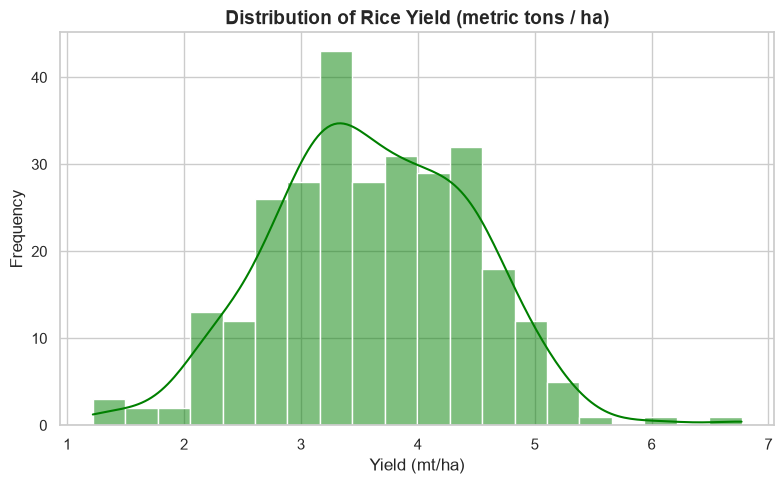

In [18]:
# target distribution (visualization 1)
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="yield_mt_ha", kde=True, bins=20, color="green", ax=ax)
ax.set_title("Distribution of Rice Yield (metric tons / ha)", fontsize=14, fontweight="bold")
ax.set_xlabel("Yield (mt/ha)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "yield_distribution.png", dpi=300)
plt.show()

C:\Users\Charles\AppData\Local\Temp\ipykernel_12724\46404228.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="ecosystem", y="yield_mt_ha", ax=axes[0], palette="Set2")
C:\Users\Charles\AppData\Local\Temp\ipykernel_12724\46404228.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="season_period", y="yield_mt_ha", ax=axes[1], palette="Set3")
C:\Users\Charles\AppData\Local\Temp\ipykernel_12724\46404228.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="ecosystem", y="yield_mt_ha", palette="Set2")
C:\User

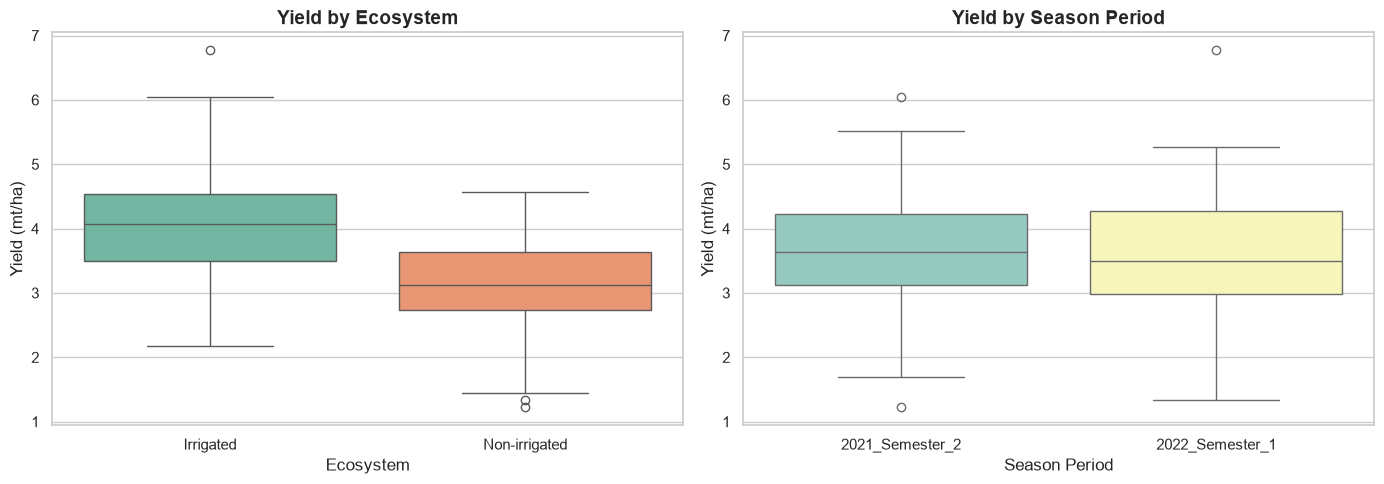

In [19]:
# yield by ecosystem and season (visualization 2 & 3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# plot 1: Ecosystem
sns.boxplot(data=df, x="ecosystem", y="yield_mt_ha", ax=axes[0], palette="Set2")
axes[0].set_title("Yield by Ecosystem", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Ecosystem", fontsize=12)
axes[0].set_ylabel("Yield (mt/ha)", fontsize=12)

# plot 2: Season
sns.boxplot(data=df, x="season_period", y="yield_mt_ha", ax=axes[1], palette="Set3")
axes[1].set_title("Yield by Season Period", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Season Period", fontsize=12)
axes[1].set_ylabel("Yield (mt/ha)", fontsize=12)

plt.tight_layout()

fig_eco, _ = plt.subplots(figsize=(6,5))
sns.boxplot(data=df, x="ecosystem", y="yield_mt_ha", palette="Set2")
plt.title("Yield by Ecosystem")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "yield_by_ecosystem.png", dpi=300)
plt.close(fig_eco)

fig_season, _ = plt.subplots(figsize=(6,5))
sns.boxplot(data=df, x="season_period", y="yield_mt_ha", palette="Set3")
plt.title("Yield by Season")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "yield_by_season.png", dpi=300)
plt.close(fig_season)

plt.show()

In [20]:
# outlier investigation
Q1 = df["yield_mt_ha"].quantile(0.25)
Q3 = df["yield_mt_ha"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Yield IQR Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Overall Yield Range: [{df['yield_mt_ha'].min():.2f}, {df['yield_mt_ha'].max():.2f}]")

outliers = df[(df["yield_mt_ha"] < lower_bound) | (df["yield_mt_ha"] > upper_bound)]

print(f"\nFound {len(outliers)} outlier(s):")
display_cols = ["province", "island_group", "ecosystem", "season_period", "yield_mt_ha", "total_fertilizer_kg_ha"]
outliers[display_cols]

Yield IQR Bounds: [1.23, 6.05]
Overall Yield Range: [1.22, 6.77]

Found 2 outlier(s):


,province,island_group,ecosystem,season_period,yield_mt_ha,total_fertilizer_kg_ha
81,Davao Occidental,Mindanao,Non-irrigated,2021_Semester_2,1.22,169.43
188,Nueva Ecija,Luzon,Irrigated,2022_Semester_1,6.77,599.78


Yield skewness: 0.06


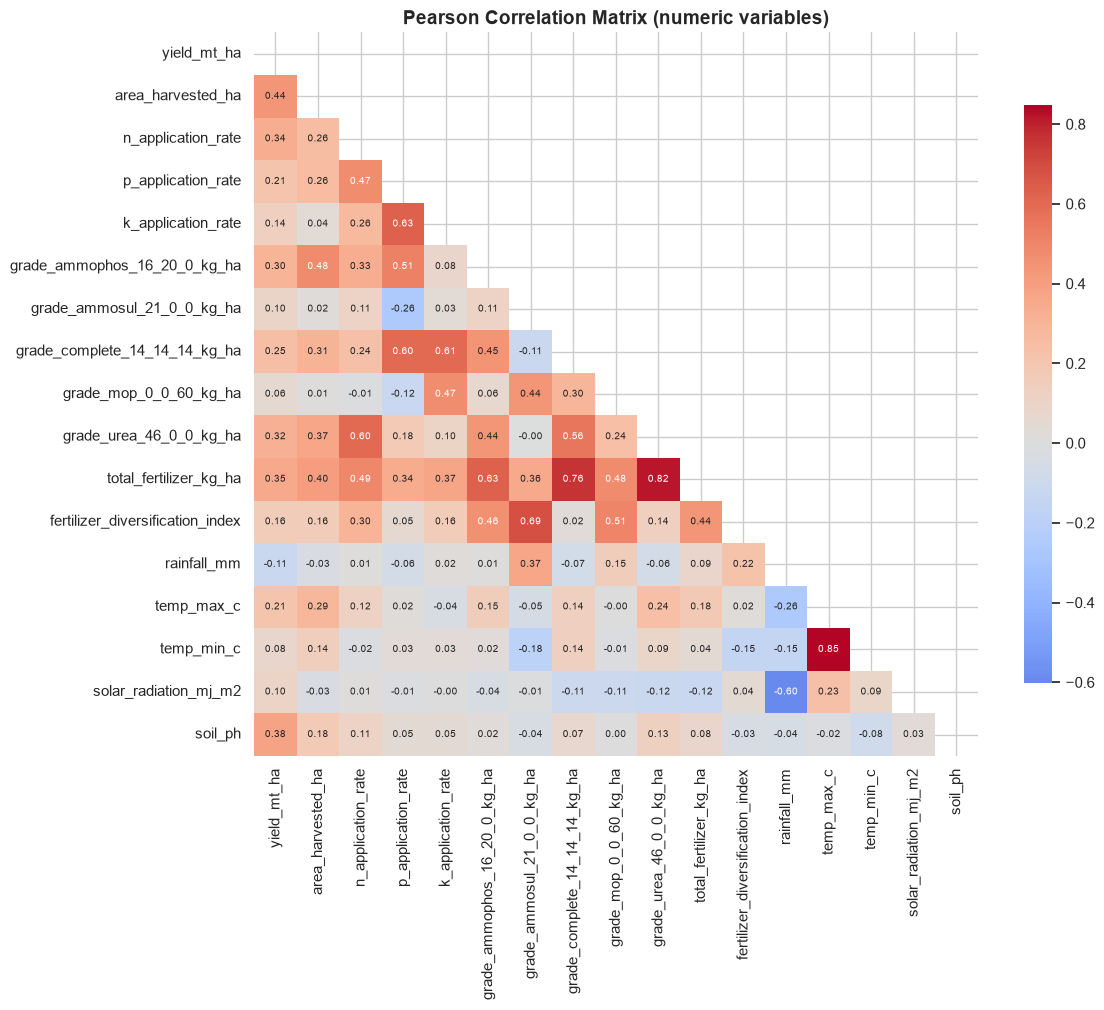

In [21]:
# skewness and correlation analysis (visualization 4)
import numpy as np

print("Yield skewness:", round(df["yield_mt_ha"].skew(), 3))

numeric_cols = df.select_dtypes(include="number").columns.tolist()
corr = df[numeric_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))  # show lower triangle only
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7}, ax=ax
)
ax.set_title("Pearson Correlation Matrix (numeric variables)", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=300)
plt.show()

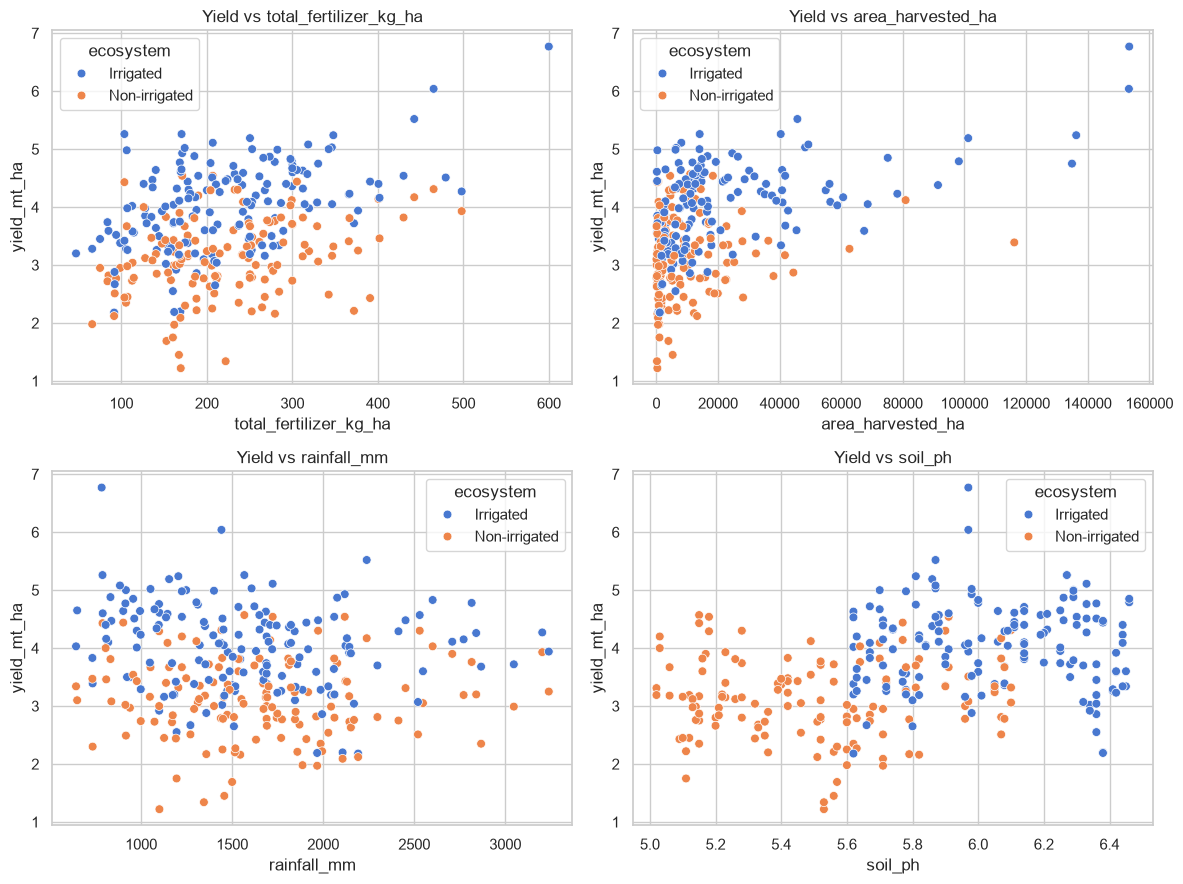

In [22]:
# yield vs key features (visualization 5)
scatter_features = ["total_fertilizer_kg_ha", "area_harvested_ha", "rainfall_mm", "soil_ph"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feat in zip(axes.flat, scatter_features):
    sns.scatterplot(data=df, x=feat, y="yield_mt_ha", hue="ecosystem", s=40, ax=ax)
    ax.set_title(f"Yield vs {feat}")
    ax.set_xlabel(feat)
    ax.set_ylabel("yield_mt_ha")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "yield_vs_key_features.png", dpi=300)
plt.show()

In [23]:
# correlation analysis
target_corr = corr["yield_mt_ha"].drop("yield_mt_ha").sort_values(ascending=False)
print("Pearson correlation with yield_mt_ha:")
print(target_corr.round(3))

feature_corr = corr.drop(index="yield_mt_ha", columns="yield_mt_ha")
cols = feature_corr.columns
pairs = [
    (cols[i], cols[j], round(feature_corr.iloc[i, j], 3))
    for i in range(len(cols))
    for j in range(i + 1, len(cols))
    if abs(feature_corr.iloc[i, j]) >= 0.80
]
pairs_df = pd.DataFrame(pairs, columns=["feature_a", "feature_b", "pearson_r"])
print("\nFeature pairs with |r| >= 0.80 (redundancy candidates):")
print(pairs_df if not pairs_df.empty else "None")

Pearson correlation with yield_mt_ha:
area_harvested_ha                   0.437
soil_ph                             0.380
total_fertilizer_kg_ha              0.353
n_application_rate                  0.335
grade_urea_46_0_0_kg_ha             0.316
grade_ammophos_16_20_0_kg_ha        0.302
grade_complete_14_14_14_kg_ha       0.248
temp_max_c                          0.214
p_application_rate                  0.214
fertilizer_diversification_index    0.164
k_application_rate                  0.136
solar_radiation_mj_m2               0.102
grade_ammosul_21_0_0_kg_ha          0.095
temp_min_c                          0.076
grade_mop_0_0_60_kg_ha              0.060
rainfall_mm                        -0.112
Name: yield_mt_ha, dtype: float64

Feature pairs with |r| >= 0.80 (redundancy candidates):
                 feature_a               feature_b  pearson_r
0  grade_urea_46_0_0_kg_ha  total_fertilizer_kg_ha      0.818
1               temp_max_c              temp_min_c      0.848


## EDA Step 3: Feature engineering and final feature matrix

In [24]:
# area diagnostic
print("Area skewness:", round(df["area_harvested_ha"].skew(), 3))

print("\nMean harvested area by ecosystem:")
print(df.groupby("ecosystem")["area_harvested_ha"].mean().round(0))

print("\nMean harvested area by season:")
print(df.groupby("season_period")["area_harvested_ha"].mean().round(0))

Area skewness: 3.158

Mean harvested area by ecosystem:
ecosystem
Irrigated        21746.0
Non-irrigated     9850.0
Name: area_harvested_ha, dtype: float64

Mean harvested area by season:
season_period
2021_Semester_2    17616.0
2022_Semester_1    14568.0
Name: area_harvested_ha, dtype: float64


In [25]:
# feat eng
df["temp_mean_c"] = (df["temp_max_c"] + df["temp_min_c"]) / 2
df["temp_range_c"] = df["temp_max_c"] - df["temp_min_c"]

cols_to_drop = [
    "temp_max_c",
    "temp_min_c",
    "grade_ammophos_16_20_0_kg_ha",
    "grade_ammosul_21_0_0_kg_ha",
    "grade_complete_14_14_14_kg_ha",
    "grade_mop_0_0_60_kg_ha",
    "grade_urea_46_0_0_kg_ha",
    "province", 
]

df_features = df.drop(columns=cols_to_drop)

print(f"Original dataset columns: {df.shape[1]}")
print(f"Final dataframe columns: {df_features.shape[1]}")
print("\nFinal columns:")
for col in df_features.columns:
    print(f"- {col}")

Original dataset columns: 23
Final dataframe columns: 15

Final columns:
- season_period
- ecosystem
- island_group
- yield_mt_ha
- area_harvested_ha
- n_application_rate
- p_application_rate
- k_application_rate
- total_fertilizer_kg_ha
- fertilizer_diversification_index
- rainfall_mm
- solar_radiation_mj_m2
- soil_ph
- temp_mean_c
- temp_range_c
